# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd
brut = pd.read_csv("donnees/consommation_brut.csv")
print(brut.shape)
print(brut.dtypes)
print(brut.isna().sum())
print(brut.duplicated().sum())

(300, 4)
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print(brut["quartier"].nunique())
print(brut["quartier"].unique())

43
<ArrowStringArray>
[   'Bas-Peu-de-Chose',    'bas-peu-de-chose',   'Bas-Peu-de-Chose ',
   ' Bas-Peu-de-Chose',    'BAS-PEU-DE-CHOSE',          'BOIS-VERNA',
          'Bois-Verna',        'Centre-ville',        'centre-ville',
       'Centre-ville ',        'CENTRE-VILLE',           'Delmas 33',
          'Delmas 33 ',          ' Delmas 33',           'DELMAS 33',
           'Delmas 65',          ' Delmas 65',           'delmas 65',
           'Delmas 75',           'delmas 75',          'Delmas 75 ',
          ' Delmas 75',           'Thomassin',          'Thomassin ',
          ' Thomassin',           'THOMASSIN',  'Place Saint-Pierre',
  'PLACE SAINT-PIERRE', 'Place Saint-Pierre ',  'place saint-pierre',
 ' Place Saint-Pierre',      'Morne Calvaire',     ' Morne Calvaire',
            'Carénage',           'Carénage ',            'CARÉNAGE',
            'carénage',           ' Carénage',              'Rue 15',
             'Rue 15 ',              'RUE 15',         'Petite-Anse'

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
convertis = pd.to_numeric(brut["kwh"], errors ="coerce")
problemes = brut[convertis.isna() & brut["kwh"].notna()]
print(problemes["kwh"].unique())

<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = (propre["kwh"].str.replace("kwh", "", case=False).str.replace(r"\s+", "", regex=True))
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
print(propre["kwh"].isna().sum())

9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")
officiels = {n.lower(): n for n in quartiers["quartier"]}
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(officiels)
print(propre["quartier"].isna().sum())
print(propre["quartier"].nunique())

0
12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
print(propre.shape)                       
propre = propre.dropna(subset=["kwh"])
print(propre.shape)

(288, 4)
(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grand = propre["kwh"] > 3 * mediane
print(propre[trop_grand])                 
propre.loc[trop_grand, "kwh"] = propre.loc[trop_grand, "kwh"] / 10
print(propre["kwh"].max())                

        mois        quartier        kwh  heures_courant
90   2025-02       Delmas 33  3602600.0            10.1
140  2025-02       Delmas 75  2012700.0            11.1
200  2024-02  Morne Calvaire  1439200.0            11.4
251  2024-01          Rue 15   997700.0             5.9
742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
ref = pd.read_csv("donnees/consommation.csv")

# commune : jointure sur quartier (variable `quartiers` de la question 5)
test = propre.merge(quartiers[["quartier", "commune"]], on="quartier", how="left")
print(test.shape)   # doit rester (279, 5)

# kwh en entier (après la correction /10 : plus de décimales)
test["kwh"] = test["kwh"].astype("int64")

# même ordre de colonnes et de lignes que la référence
test = test[ref.columns].sort_values(["mois", "quartier"]).reset_index(drop=True)
ref2 = ref.sort_values(["mois", "quartier"]).reset_index(drop=True)

print(test.equals(ref2))   # attendu

(279, 5)
False


In [9]:
print(ref.shape)
print(ref.isna().sum())

# quelles lignes de la référence manquent dans propre ?
cles = ["mois", "quartier"]
manquantes = ref.merge(test[cles], on=cles, how="left", indicator=True)
manquantes = manquantes[manquantes["_merge"] == "left_only"]
print(manquantes)

(288, 5)
mois              0
quartier          0
commune           0
kwh               0
heures_courant    0
dtype: int64
        mois      quartier         commune     kwh  heures_courant     _merge
31   2024-08    Bois-Verna  Port-au-Prince  182920             8.5  left_only
43   2025-08    Bois-Verna  Port-au-Prince  202530             9.7  left_only
64   2025-05  Centre-ville  Port-au-Prince  413200            11.1  left_only
91   2025-08     Delmas 33          Delmas  470080            10.9  left_only
109  2025-02     Delmas 65          Delmas  332910            12.9  left_only
113  2025-06     Delmas 65          Delmas  375840            13.5  left_only
228  2025-01      Carénage     Cap-Haïtien  132520            11.3  left_only
231  2025-04      Carénage     Cap-Haïtien  144360            10.5  left_only
243  2024-04        Rue 15     Cap-Haïtien  189770             9.6  left_only


In [10]:
commun = ref2.merge(test[cles], on=cles, how="inner").sort_values(cles).reset_index(drop=True)
print(commun.shape)                       
print(test.equals(commun))                

(279, 5)
True


Réponse à la question 8 : True.

La comparaison directe donne False : "propre" n'a pas la colonne "commune" et "kwh" n'a pas le même type que dans la référence. Après avoir ajouté la commune et converti "kwh" en entier, il reste un écart de taille : "consommation.csv" contient 288 lignes, "propre" en a 279. Les 9 lignes en plus sont celles dont le "kwh" était manquant dans le fichier brut (tableau ci-dessus). Je les ai supprimées plutôt que d'inventer des valeurs.

Sur les 279 lignes communes (clés "mois" et "quartier"), "propre" est identique à la référence : "equals" renvoie True. Le nettoyage est validé.

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

In [11]:
print(propre.shape)

(279, 4)


**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [14]:

avant = len(propre)
avec_quartiers = propre.merge(quartiers, on="quartier", how="left")
print(avant, "->", len(avec_quartiers))   

avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

bpc = avec_quartiers[(avec_quartiers["quartier"] == "Bas-Peu-de-Chose")  & (avec_quartiers["mois"] == "2024-01")]
print(bpc[["quartier", "mois", "kwh_par_abonne"]])   

279 -> 279
           quartier     mois  kwh_par_abonne
0  Bas-Peu-de-Chose  2024-01            85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [15]:
meteo = pd.read_csv("donnees/meteo.csv")

avant = len(avec_quartiers)
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left")
print(avant, "->", len(avec_meteo))           
print(avec_meteo["temperature_c"].isna().sum())   

279 -> 279
0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [16]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

relu = pd.read_csv("donnees/consommation_propre.csv")
print(relu.shape)   

(279, 11)


Les deux jointures (quartiers sur "quartier", météo sur "mois" + "commune") sont de type left et conservent 279 lignes : aucune ligne perdue ni dupliquée, aucune température manquante. Le fichier "donnees/consommation_propre.csv" (279 lignes, 11 colonnes) est écrit sans index ; c'est lui que lira le tableau de bord.

## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [17]:
df = pd.read_csv("donnees/consommation_propre.csv")

par_type = df.groupby("type")["kwh_par_abonne"].mean().round(1)
print(par_type)          

classement = (df.groupby("quartier")["kwh_par_abonne"].mean() .round(1).sort_values(ascending=False))
print(classement)        

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


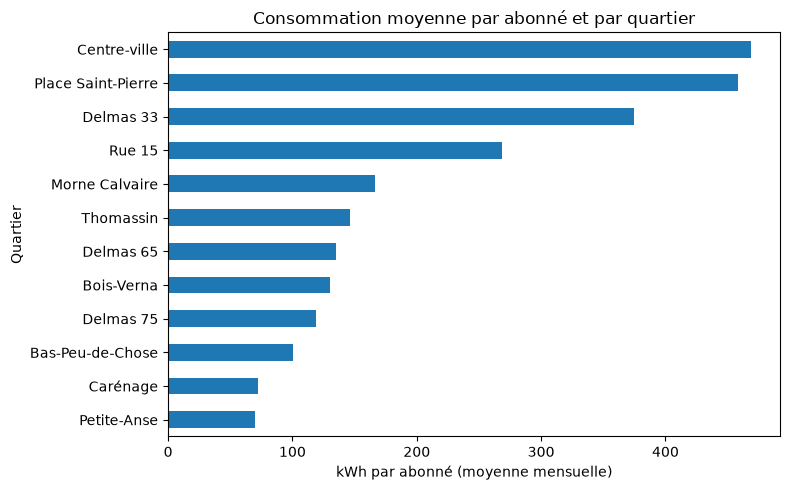

In [18]:
import matplotlib.pyplot as plt

classement.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Consommation moyenne par abonné et par quartier")
plt.xlabel("kWh par abonné (moyenne mensuelle)")
plt.ylabel("Quartier")
plt.tight_layout()
plt.show()

Les quartiers commerciaux consomment 393.2 kWh par abonnes contre 117.4 pour les residentiels ; centre-ville arrive en tete avec 468.7.

**Ce qu'on en conclut :**

Le type de quartier explique l'ecart, les quartiers commerciaux consomment plus de trois fois plus par abonne que les residentiels

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

In [19]:
import matplotlib.pyplot as plt
df = pd.read_csv("donnees/consommation_propre.csv")

In [20]:
tab = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
tab["hausse_pct"] = (tab[2025] / tab[2024] - 1) * 100   

res = pd.DataFrame({
    "2024 (M kWh)": (tab[2024] / 1e6).round(2),
    "2025 (M kWh)": (tab[2025] / 1e6).round(2),
    "hausse (%)": tab["hausse_pct"].round(1),
}).sort_values("2025 (M kWh)", ascending=False)
print(res)

                2024 (M kWh)  2025 (M kWh)  hausse (%)
commune                                               
Delmas                 11.61         11.74         1.1
Port-au-Prince         10.09         10.31         2.3
Pétion-Ville            8.60          9.68        12.6
Cap-Haïtien             4.59          5.62        22.5


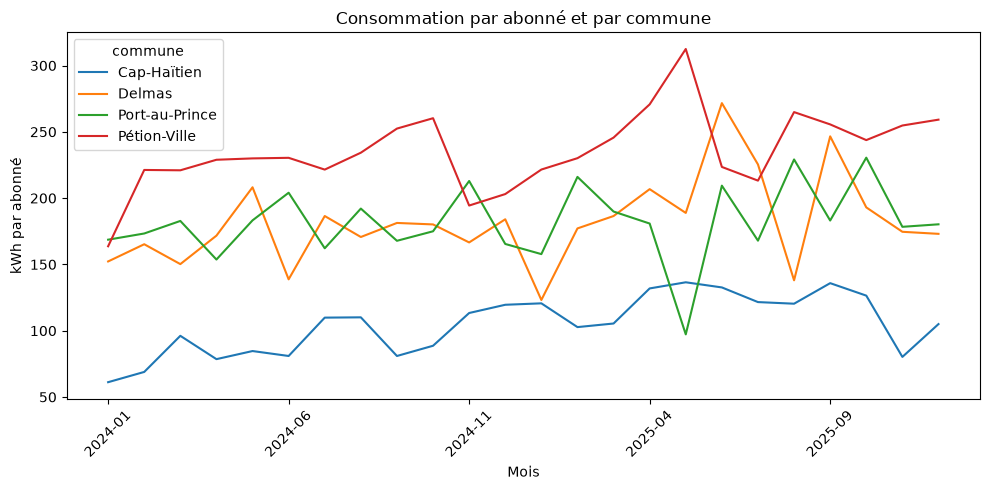

In [21]:
g = df.groupby(["mois", "commune"])[["kwh", "abonnes"]].sum()
courbe = (g["kwh"] / g["abonnes"]).unstack()
courbe.plot(figsize=(10, 5))
plt.title("Consommation par abonné et par commune")
plt.xlabel("Mois")
plt.ylabel("kWh par abonné")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

Delmas consomme le plus (11.74 millions de kWh en 2025) mais reste presque stable (+1.1 %), alors que Cap-Haïtien, le plus petit (5.62 millions), progresse le plus : +22.5 %. Par abonné, Pétion-Ville consomme le plus et Cap-Haïtien le moins, mais la courbe de Cap-Haïtien a une tendance à la hausse sur les deux ans, en accord avec sa forte hausse.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.